In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

USE_FINETUNED = False

BASE_MODEL = "amazon/chronos-2"
LOCAL_CKPT = "chronos-2-tep-sp-3runs-ctx2048-lora-final"   # saved by TEP-Chronos2-FineTune.ipynb
HF_REPO_ID = "Imker0311/chronos-2-tep-sp-3runs-ctx2048-lora"


def resolve_checkpoint(finetuned):
    if not finetuned:
        return BASE_MODEL
    if Path(LOCAL_CKPT).is_dir():
        return LOCAL_CKPT
    from huggingface_hub import snapshot_download
    return snapshot_download(repo_id=HF_REPO_ID, repo_type="model")


device = "cuda" if torch.cuda.is_available() else "cpu"
CHECKPOINT = resolve_checkpoint(USE_FINETUNED)
kwargs = dict(device_map=device)
if USE_FINETUNED:
    kwargs["import_allowlist"] = ["chronos.chronos2.model"]
pipeline = Chronos2Pipeline.from_pretrained(CHECKPOINT, **kwargs)

MODEL_LABEL = "Chronos-2 fine-tuned" if USE_FINETUNED else "Chronos-2"
MAX_CONTEXT = pipeline.model_context_length
MAX_HORIZON = pipeline.model_prediction_length
print(f"Loaded {MODEL_LABEL} from {CHECKPOINT} on {device}")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded Chronos-2 from amazon/chronos-2 on cuda


In [2]:
# Load data
import json

DATA_FILE = "tep_sp_spaced_6min_noisy.h5"


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_h = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    if "y" in f:   # true valve positions
        groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])
    config = json.loads(f.attrs["config"])
SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)

nominal = {int(k): v for k, v in config["setpoints"].items()}
CHANGED = sorted({k for k, _, _ in config["setpoint_schedule"]})   # set points changed in this run
t_test = config.get("t_test")                                    # start of the test changes (h)

sp = groups["sp"][0]
off = {k: np.abs(sp[:, k - 1] - nominal[k]) > 1e-9 for k in CHANGED}
sp_change = np.zeros(len(time_h), dtype=int)
for k in reversed(CHANGED):
    sp_change[off[k]] = k

data = {"time_h": time_h, "sp_change": sp_change}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(df), freq=f"{config['record_every']}s"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({time_h[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
print(f"changed set points: {CHANGED}, test part from {t_test} h")
df.head()

6798 samples (680 h), 53 targets, covariate groups: dist (12), sp (20), valve (12)
changed set points: [5, 7, 8, 11, 13, 14, 15, 17, 18, 19, 20], test part from 580.6 h


,item_id,timestamp,time_h,sp_change,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:00:00,0.1,0,0.250570,3646.911201,4529.162678,9.361743,26.955182,42.374646,...,24.683121,61.476138,22.362808,40.095187,38.413928,46.439184,47.490184,40.948926,17.063033,50.0
1,tep,2026-01-01 00:06:00,0.2,0,0.251641,3685.782817,4532.305731,9.392197,27.192827,42.306830,...,24.669825,61.220980,22.282045,39.990620,38.834873,46.076364,47.465945,40.781658,19.495237,50.0
2,tep,2026-01-01 00:12:00,0.3,0,0.224798,3649.568095,4485.146695,9.372377,26.672050,42.430624,...,21.892922,61.453199,22.133312,40.754288,37.087577,47.823150,47.578868,40.150284,16.873578,50.0
3,tep,2026-01-01 00:18:00,0.4,0,0.218406,3639.328339,4472.573385,9.490855,26.897409,42.106486,...,21.619293,61.542878,22.350442,40.748417,34.570768,46.721658,47.682376,40.822785,17.567854,50.0
4,tep,2026-01-01 00:24:00,0.5,0,0.259690,3665.940633,4583.163603,9.290618,27.026282,42.238532,...,25.661680,61.170016,21.863833,42.083198,38.107019,48.403660,47.805239,40.148750,18.059470,50.0


In [3]:
# Forecast window
events = []   # (start index, end index, set point, new value)
for k in CHANGED:
    on = off[k]
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k, sp[start, k - 1]))
events.sort()

EVENT_INDEX = 68
BUFFER = 20          # nominal samples before the event at the start of the forecast
HORIZON = 200
PLOT_LEAD_IN = 200   # context samples shown in the figure

event_start, event_end, event_sp, event_value = events[EVENT_INDEX]
SPLIT = max(event_start - BUFFER, 0)
HORIZON = min(HORIZON, MAX_HORIZON, len(df) - SPLIT)
context_df = df.iloc[SPLIT - min(SPLIT, MAX_CONTEXT):SPLIT]
truth_df = df.iloc[SPLIT:SPLIT + HORIZON]
lead = df.iloc[max(SPLIT - PLOT_LEAD_IN, 0):SPLIT]
print(f"Event {EVENT_INDEX}: SP {event_sp} {LABELS[f'sp_{event_sp}']} "
      f"{nominal[event_sp]:.4g} -> {event_value:.4g} ({100 * (event_value - nominal[event_sp]) / nominal[event_sp]:+.1f}%)")
print(f"Forecast from sample {SPLIT} ({time_h[SPLIT]:.1f} h), horizon {HORIZON} samples, context {len(context_df)} samples")

Event 68: SP 14 Reactor feed D (mol%) 6.882 -> 7.082 (+2.9%)
Forecast from sample 5943 (594.4 h), horizon 200 samples, context 5943 samples


In [4]:
# Covariate cases, every covariate is known over the forecast
SP_COVARIATES = [f"sp_{k}" for k in CHANGED]
CASES = {
    "Set points": SP_COVARIATES,
    "Set points + disturbances": SP_COVARIATES + COLUMNS["dist"],
}

SCORED = COLUMNS["xmeas"]   # measurements only, no valves
SCALE = df[SCORED].std()    # standard deviation over the whole dataset
for case, covariates in CASES.items():
    print(f"{case} ({len(covariates)}): {', '.join(covariates)}")

Set points (11): sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15, sp_17, sp_18, sp_19, sp_20
Set points + disturbances (23): sp_5, sp_7, sp_8, sp_11, sp_13, sp_14, sp_15, sp_17, sp_18, sp_19, sp_20, dist_1, dist_2, dist_3, dist_4, dist_5, dist_6, dist_7, dist_8, dist_9, dist_10, dist_11, dist_12


In [5]:
# Metrics
QUANTILES = [0.1, 0.5, 0.9]
ALPHA = round(1 - (QUANTILES[-1] - QUANTILES[0]), 6)   # 0.2 for the 10-90% interval
METRICS = ["scaled MAE", "MAPE (%)", "coverage", "scaled Winkler"]


def winkler(actual, lower, upper, alpha):
    """Winkler interval score at every step."""
    width = upper - lower
    below = width + 2 / alpha * (lower - actual)
    above = width + 2 / alpha * (actual - upper)
    return np.where(actual < lower, below, np.where(actual > upper, above, width))


def score_event(forecast, truth_df):
    """Metrics per scored variable for one forecast, forecast[col] = (point forecast, lower, upper)."""
    rows = {}
    for col in SCORED:
        pred, lower, upper = forecast[col]
        actual = truth_df[col].to_numpy()
        rows[col] = {
            "scaled MAE": np.mean(np.abs(pred - actual)) / SCALE[col],
            "MAPE (%)": 100 * np.mean(np.abs(actual - pred) / np.abs(actual)),
            "coverage": np.mean((actual >= lower) & (actual <= upper)),
            "scaled Winkler": np.mean(winkler(actual, lower, upper, ALPHA)) / SCALE[col],
        }
    return pd.DataFrame(rows).T

In [6]:
# Chronos-2 forecast of one window
def run_forecast(context_df, truth_df, used, future, past_only):
    future_df = None
    if future:
        future_df = truth_df[["item_id", "timestamp"] + future]

    pred_df = pipeline.predict_df(
        context_df[["item_id", "timestamp"] + TARGET_COLUMNS + used],
        future_df=future_df,
        prediction_length=len(truth_df),
        quantile_levels=QUANTILES,
        id_column="item_id",
        timestamp_column="timestamp",
        target=TARGET_COLUMNS,
    )
    forecast = {}
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        forecast[col] = (sub["predictions"].to_numpy(), sub[str(QUANTILES[0])].to_numpy(),
                         sub[str(QUANTILES[-1])].to_numpy())
    return forecast

In [7]:
# Forecast with each covariate case
window_df = pd.concat([context_df, truth_df])
forecasts, per_variable = {}, {}
for case, covariates in CASES.items():
    used = [c for c in covariates if window_df[c].nunique() > 1]   # constant covariates carry no information
    forecasts[case] = run_forecast(context_df, truth_df, used, used, [])
    per_variable[case] = score_event(forecasts[case], truth_df)
    print(f"{case}: {len(used)} covariates used")

scores = pd.DataFrame({case: s.mean() for case, s in per_variable.items()}).T[METRICS]
print(f"{MODEL_LABEL}, event {EVENT_INDEX}: mean over {len(SCORED)} measurements")
scores.round(3)

Set points: 11 covariates used


Set points + disturbances: 23 covariates used
Chronos-2, event 68: mean over 41 measurements


,scaled MAE,MAPE (%),coverage,scaled Winkler
Set points,0.470,5.796,0.879,2.153
Set points + disturbances,0.467,5.772,0.882,2.162


In [8]:
# Measurements where the two forecasts differ most
first, second = list(CASES)
ranking = pd.DataFrame({
    "description": [LABELS[col] for col in SCORED],
    "scaled difference": [np.mean(np.abs(forecasts[second][col][0] - forecasts[first][col][0])) / SCALE[col]
                          for col in SCORED],   # mean gap between the two forecasts / std over the dataset
    f"scaled MAE ({first})": per_variable[first]["scaled MAE"].to_numpy(),
    f"scaled MAE ({second})": per_variable[second]["scaled MAE"].to_numpy(),
}, index=SCORED).sort_values("scaled difference", ascending=False)
ranking.head(10).round(3)

,description,scaled difference,scaled MAE (Set points),scaled MAE (Set points + disturbances)
xmeas_28,Reactor feed F (mol%),0.180,0.599,0.461
xmeas_10,Purge rate (kscmh),0.151,0.292,0.252
xmeas_38,Product E (mol%),0.142,0.501,0.582
xmeas_34,Purge F (mol%),0.128,0.538,0.439
xmeas_29,Purge A (mol%),0.116,0.400,0.377
xmeas_4,A and C feed (kscmh),0.115,0.383,0.401
xmeas_1,A feed (kscmh),0.114,0.446,0.453
xmeas_21,Reactor CW outlet temp (C),0.102,0.427,0.417
xmeas_33,Purge E (mol%),0.100,0.377,0.365
xmeas_24,Reactor feed B (mol%),0.097,0.350,0.359


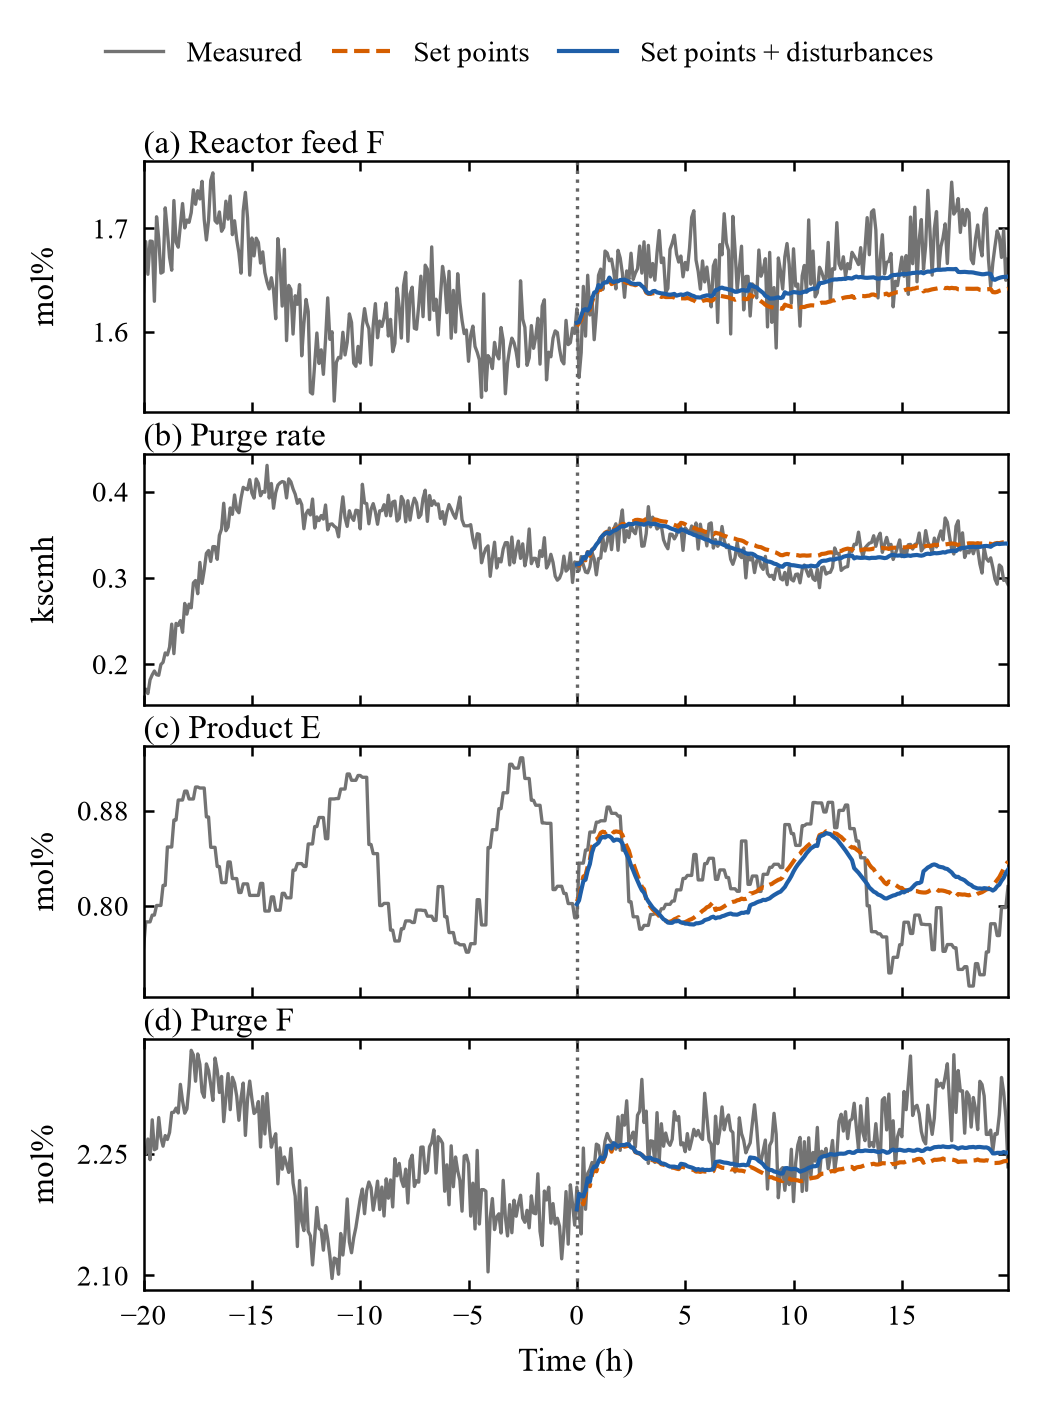

Saved Figures/chronos2_disturbance_covariates_article.pdf and .png


In [9]:
# Article figure: both covariate cases in one plot
import re
from matplotlib.ticker import MaxNLocator

N_COLUMNS = 4
ARTICLE_COLUMNS = list(ranking.index[:N_COLUMNS])   # or a fixed list such as ["xmeas_6", "xmeas_7", "xmeas_21", "xmeas_11"]
SHOW_INTERVALS = False
FIGURE_DIR = "Figures"
FIGURE_NAME = "chronos2_disturbance_covariates_article"
CASE_COLORS = ["#d55e00", "#1f5fa8"]   # colour-blind safe, one per case
CASE_LINESTYLES = ["--", "-"]          # also readable in black and white
ARTICLE_STYLE = {
    "figure.dpi": 300,   # sharp figure in the notebook, the saved files use dpi=600
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}


def split_label(label):
    match = re.fullmatch(r"(.*?)\s*\((.*)\)", label)
    if match is None:
        return label, ""
    name, unit = match.groups()
    name = re.sub(r" temp$", " temperature", name.replace("CW", "cooling water"))
    return name, {"C": "°C", "m3/h": "m³/h"}.get(unit, unit)


t0 = truth_df["time_h"].iloc[0]   # forecast start becomes time 0
measured_t = np.concatenate([lead["time_h"], truth_df["time_h"]]) - t0
forecast_t = truth_df["time_h"].to_numpy() - t0
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(len(ARTICLE_COLUMNS), 1, figsize=(3.5, 1.1 * len(ARTICLE_COLUMNS)), sharex=True)
    for letter, ax, col in zip("abcdefgh", axes, ARTICLE_COLUMNS):
        name, unit = split_label(LABELS[col])
        ax.plot(measured_t, np.concatenate([lead[col], truth_df[col]]), color="0.45", lw=0.8, label="Measured")
        for case, color, ls in zip(CASES, CASE_COLORS, CASE_LINESTYLES):
            pred, lower, upper = forecasts[case][col]
            if SHOW_INTERVALS:
                ax.fill_between(forecast_t, lower, upper, color=color, alpha=0.15, lw=0)
            ax.plot(forecast_t, pred, color=color, ls=ls, lw=1.0, zorder=3, label=case)
        ax.axvline(0, color="0.4", ls=":", lw=0.8)
        ax.set_title(f"({letter}) {name}", loc="left", pad=2)
        ax.set_ylabel(unit)
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.margins(x=0)
    axes[-1].set_xlabel("Time (h)")
    fig.align_ylabels(axes)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.tight_layout(h_pad=0.3)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(labels), frameon=False,
               handlelength=2.0, columnspacing=1.0)

    os.makedirs(FIGURE_DIR, exist_ok=True)
    for ext in ["pdf", "png"]:
        fig.savefig(f"{FIGURE_DIR}/{FIGURE_NAME}.{ext}", dpi=600, bbox_inches="tight")
    plt.show()
print(f"Saved {FIGURE_DIR}/{FIGURE_NAME}.pdf and .png")